# Exploratory Data Analysis EDA

This notebook is dedicated to performing Exploratory Data Analysis (EDA) on the raw data of the Tanzania Tourism project.



## Main Objectives of the Analysis

- Understand the basic structure of the dataset.
- Identify the data types of each column, such as numerical and categorical data.
- Examine missing values and determine the most appropriate strategy for handling them based on their characteristics.
- Analyze data distributions and tails.
- Explore the relationships between the target variable and the other features.
- Identify data quality issues.
- Prepare the data for the data preprocessing and machine learning stages.

## 1. Import Required Libraries

The following libraries are used throughout the analysis:

- `Path` for handling file and directory paths in a platform-independent way.
- `sys` for interacting with Python's runtime environment and modifying the module search path.
- `NumPy` for numerical operations.
- `Pandas` for data manipulation and analysis.
- `Matplotlib` and `Seaborn` for visualization.
- `MaxNLocator` for controlling the number of ticks in plots.


In [43]:
import sys
from pathlib import Path

notebook_dir = Path.cwd()
project_root = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import src.config as cfg
import importlib
importlib.reload(cfg)

from src.config import (
    TRAIN_DATA_PATH,
    TEST_DATA_PATH,
    ID_COL,
    TARGET_COL,
    TARGET_CLASSES,
    NUMERIC_COLS,
    CATEGORICAL_COLS,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
)

import numpy as np, pandas as pd,  matplotlib.pyplot as plt, seaborn as sns


## 2. Load Data

In [44]:
df = pd.read_csv(TRAIN_DATA_PATH)

In [45]:
df

,Tour_ID,country,age_group,travel_with,total_female,total_male,purpose,main_activity,info_source,tour_arrangement,...,package_accomodation,package_food,package_transport_tz,package_sightseeing,package_guided_tour,package_insurance,night_mainland,night_zanzibar,first_trip_tz,cost_category
0,tour_id1hffseyw,ITALY,45-64,With Children,0.0,2.0,Visiting Friends and Relatives,Beach Tourism,"Friends, relatives",Package Tour,...,Yes,Yes,Yes,No,No,No,0,7,Yes,High Cost
1,tour_idnacd7zag,UNITED KINGDOM,25-44,With Spouse,1.0,1.0,Leisure and Holidays,Wildlife Tourism,"Travel agent, tour operator",Package Tour,...,Yes,Yes,Yes,No,No,No,0,7,Yes,High Cost
2,tour_id62vz7e71,UNITED STATES OF AMERICA,65+,With Spouse,1.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,Yes,Yes,Yes,Yes,Yes,No,6,6,Yes,Higher Cost
3,tour_idrc76tzix,RWANDA,25-44,With Spouse and Children,3.0,1.0,Leisure and Holidays,Beach Tourism,"Radio, TV, Web",Independent,...,No,No,No,No,No,No,3,0,No,Lower Cost
4,tour_idn723m0n9,UNITED STATES OF AMERICA,45-64,Alone,0.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,Yes,Yes,Yes,No,Yes,Yes,7,0,Yes,Higher Cost
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18501,tour_idmp5ciw50,KENYA,45-64,Alone,0.0,1.0,Other,Hunting Tourism,Others,Independent,...,No,No,No,No,No,No,3,0,No,Lower Cost
18502,tour_ideq0yncfs,KENYA,45-64,Alone,1.0,0.0,Meetings and Conference,Wildlife Tourism,Others,Independent,...,No,No,No,No,No,No,2,0,No,Lower Cost
18503,tour_idv7pz3vs8,UNITED STATES OF AMERICA,25-44,With Spouse and Children,2.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Independent,...,No,No,No,No,No,No,9,0,Yes,Higher Cost
18504,tour_idy6ydo00w,UNITED STATES OF AMERICA,25-44,With Spouse,1.0,1.0,Leisure and Holidays,Conference Tourism,"Radio, TV, Web",Package Tour,...,Yes,Yes,Yes,Yes,Yes,No,13,4,No,Higher Cost


## 3. Initial Dataset Inspection

Before performing any cleaning or statistical analysis, we first inspect the basic structure of the dataset.

The following checks will help us understand:

- Number of observations and features.
- Data types.
- Missing values.
- Unique values.
- Basic statistical properties.

In [46]:
print('Number of observations is', df.shape[0], 'and number of features is', df.shape[1])

Number of observations is 18506 and number of features is 21


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18506 entries, 0 to 18505
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Tour_ID                18506 non-null  object 
 1   country                18506 non-null  object 
 2   age_group              18506 non-null  object 
 3   travel_with            17431 non-null  object 
 4   total_female           18504 non-null  float64
 5   total_male             18500 non-null  float64
 6   purpose                18506 non-null  object 
 7   main_activity          18506 non-null  object 
 8   info_source            18506 non-null  object 
 9   tour_arrangement       18506 non-null  object 
 10  package_transport_int  18506 non-null  object 
 11  package_accomodation   18506 non-null  object 
 12  package_food           18506 non-null  object 
 13  package_transport_tz   18506 non-null  object 
 14  package_sightseeing    18506 non-null  object 
 15  pa

In [48]:
print("Number of missing values in each column:")
print(df.isna().sum())

Number of missing values in each column:
Tour_ID                     0
country                     0
age_group                   0
travel_with              1075
total_female                2
total_male                  6
purpose                     0
main_activity               0
info_source                 0
tour_arrangement            0
package_transport_int       0
package_accomodation        0
package_food                0
package_transport_tz        0
package_sightseeing         0
package_guided_tour         0
package_insurance           0
night_mainland              0
night_zanzibar              0
first_trip_tz               0
cost_category               0
dtype: int64


In [49]:
for col in df.columns:
    print(df[col].name,'\n', df[col].unique(), '\n')

Tour_ID 
 ['tour_id1hffseyw' 'tour_idnacd7zag' 'tour_id62vz7e71' ...
 'tour_idv7pz3vs8' 'tour_idy6ydo00w' 'tour_idceoq9por'] 

country 
 ['ITALY' 'UNITED KINGDOM' 'UNITED STATES OF AMERICA' 'RWANDA' 'FRANCE'
 'SWIZERLAND' 'NIGERIA' 'AUSTRALIA' 'SPAIN' 'DENMARK' 'BELGIUM' 'ZAMBIA'
 'NETHERLANDS' 'CANADA' 'INDIA' 'NORWAY' 'ZIMBABWE' 'MORROCO' 'CHINA'
 'GERMANY' 'SOUTH AFRICA' 'JAPAN' 'UAE' 'RUSSIA' 'KENYA' 'GREECE' 'POLAND'
 'AUSTRIA' 'MALAYSIA' 'CZECH REPUBLIC' 'KOREA' 'DRC' 'CYPRUS' 'KUWAIT'
 'BRAZIL' 'CHILE' 'BULGARIA' 'UNITED ARAB EMIRATES' 'ISRAEL' 'NEW ZEALAND'
 'UGANDA' 'IRELAND' 'SWEDEN' 'QATAR' 'CONGO' 'BURUNDI' 'FINLAND' 'GHANA'
 'OMAN' 'LEBANON' 'LUXEMBOURG' 'IVORY COAST' 'NAMIBIA' 'ROMANIA'
 'THAILAND' 'SUDAN' 'SINGAPORE' 'PORTUGAL' 'MALAWI' 'MALT' 'EGYPT'
 'PAKISTAN' 'TANZANIA' 'ARGENTINA' 'SRI LANKA' 'BOTSWANA' 'VIETNAM'
 'BERMUDA' 'TAIWAN' 'SENEGAL' 'AFGHANISTAN' 'COLOMBIA' 'JAMAICA' 'BAHRAIN'
 'COSTARICA' 'COMORO' 'URUGUAY' 'SAUD ARABIA' 'ETHIOPIA' 'PHILIPINES'
 'ARMENIA'

In [50]:
df.describe(include='all')

,Tour_ID,country,age_group,travel_with,total_female,total_male,purpose,main_activity,info_source,tour_arrangement,...,package_accomodation,package_food,package_transport_tz,package_sightseeing,package_guided_tour,package_insurance,night_mainland,night_zanzibar,first_trip_tz,cost_category
count,18506,18506,18506,17431,18504.000000,18500.000000,18506,18506,18506,18506,...,18506,18506,18506,18506,18506,18506,18506.000000,18506.000000,18506,18506
unique,18506,131,5,5,NaN,NaN,8,10,8,2,...,2,2,2,2,2,2,NaN,NaN,2,6
top,tour_idceoq9por,UNITED STATES OF AMERICA,25-44,Alone,NaN,NaN,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,No,No,No,No,No,No,NaN,NaN,Yes,Normal Cost
freq,1,2846,9047,7590,NaN,NaN,11755,5988,8005,9295,...,9541,10143,10873,12786,12447,15809,NaN,NaN,12737,5471
mean,NaN,NaN,NaN,NaN,0.936230,0.998757,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,9.141576,2.493516,NaN,NaN
std,NaN,NaN,NaN,NaN,1.215582,1.173177,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,14.127449,5.275156,NaN,NaN
min,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,0.000000,1.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,0.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,0.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,11.000000,4.000000,NaN,NaN


## 4. Missing Value Analysis

Missing values can affect both exploratory analysis and machine learning models.

We will first identify the number and percentage of missing values in each feature.

In [51]:
dic = {

}

for col in df.columns:
    nan = df[col].isna().sum()
    len_of_df = len(df[col])
    re = nan / len_of_df * 100
    dic[col] = {  
    'number of missing values': nan,
    'percentage of missing values': re.astype('float32').round(2)
    }

df_missing = pd.DataFrame(dic).T
df_missing = df_missing.replace(0, '')

In [52]:
df_missing

,number of missing values,percentage of missing values
Tour_ID,,
country,,
age_group,,
travel_with,1075.0,5.81
total_female,2.0,0.01
total_male,6.0,0.03
purpose,,
main_activity,,
info_source,,
tour_arrangement,,


## 5. Duplicate Records

Duplicate observations can introduce bias into the analysis and may cause the model to see repeated examples during training.

We therefore check whether exact duplicate rows exist in the dataset.

In [53]:
print('Duplicate observations num:', df.duplicated().sum())

Duplicate observations num: 0


## 6. Numerical Feature Analysis

Numerical variables are analyzed to understand their:

- Central tendency.
- Dispersion.
- Distribution.
- Skewness.
- Potential outliers.

These characteristics can influence preprocessing and model selection.

In [54]:
print('Skewness of numeric columns:')
display(df[NUMERIC_COLS].skew())
print('Descriptive Statistics of numeric columns:')
display(df[NUMERIC_COLS].describe().T.style.background_gradient(cmap='coolwarm_r').format('{:.2f}'))

Skewness of numeric columns:


total_female       8.430881
total_male        14.625647
night_mainland     9.160400
night_zanzibar    11.165929
dtype: float64

Descriptive Statistics of numeric columns:


,count,mean,std,min,25%,50%,75%,max
total_female,18504.00,0.94,1.22,0.00,0.00,1.00,1.00,49.00
total_male,18500.00,1.00,1.17,0.00,1.00,1.00,1.00,58.00
night_mainland,18506.00,9.14,14.13,0.00,3.00,6.00,11.00,365.00
night_zanzibar,18506.00,2.49,5.28,0.00,0.00,0.00,4.00,240.00


total_female         Axes(0.125,0.11;0.168478x0.77)
total_male        Axes(0.327174,0.11;0.168478x0.77)
night_mainland    Axes(0.529348,0.11;0.168478x0.77)
night_zanzibar    Axes(0.731522,0.11;0.168478x0.77)
dtype: object

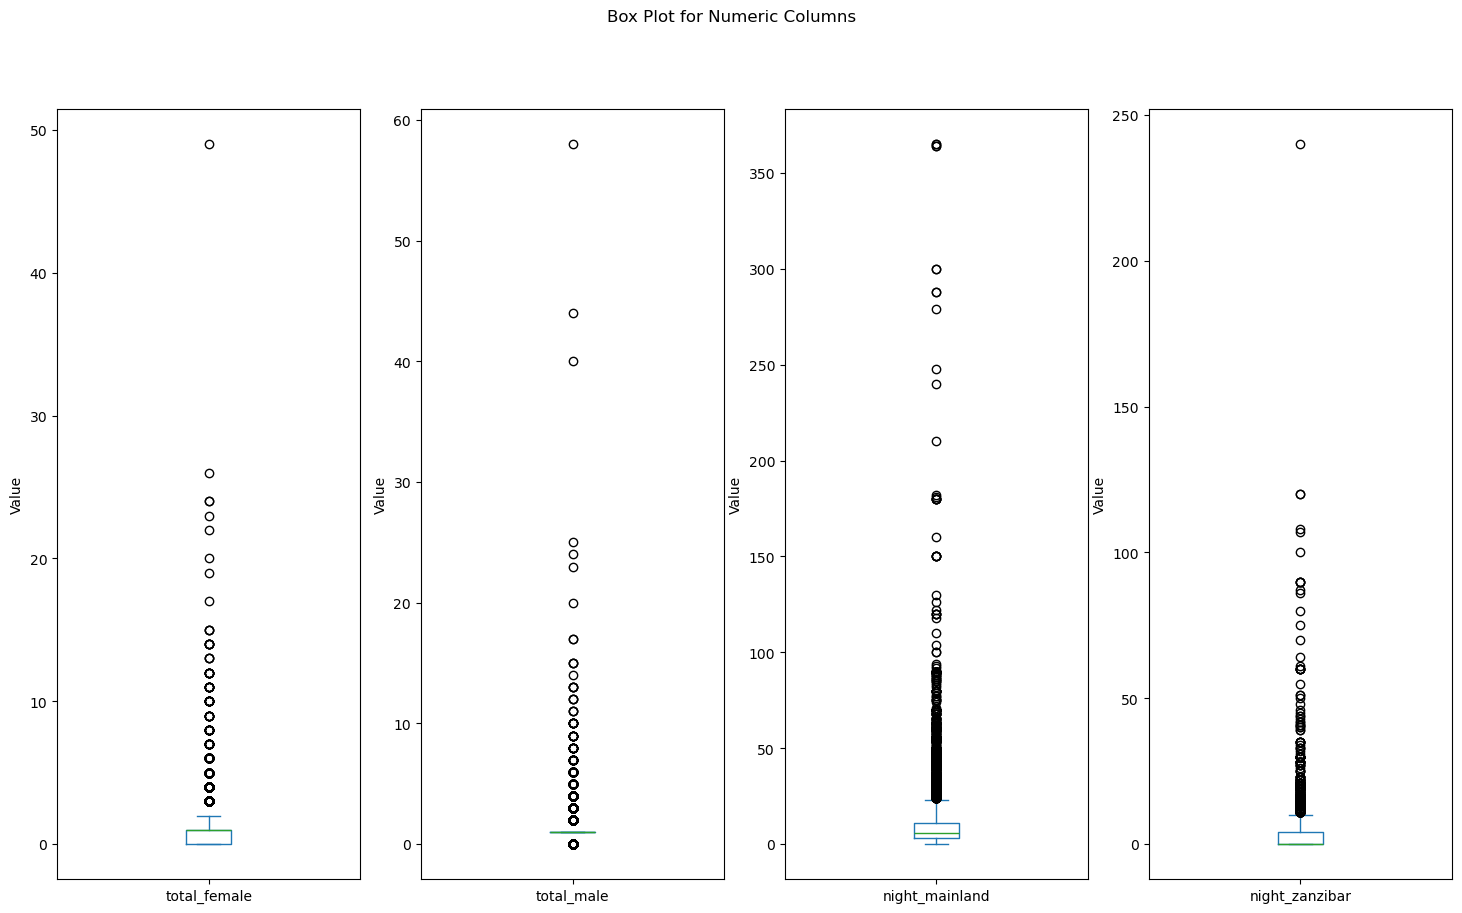

In [55]:
df[NUMERIC_COLS].plot(kind='box', subplots=True, layout=(1, 4), figsize=(18,10), title='Box Plot for Numeric Columns', ylabel='Value',)

array([[<Axes: ylabel='Density'>, <Axes: ylabel='Density'>],
       [<Axes: ylabel='Density'>, <Axes: ylabel='Density'>]], dtype=object)

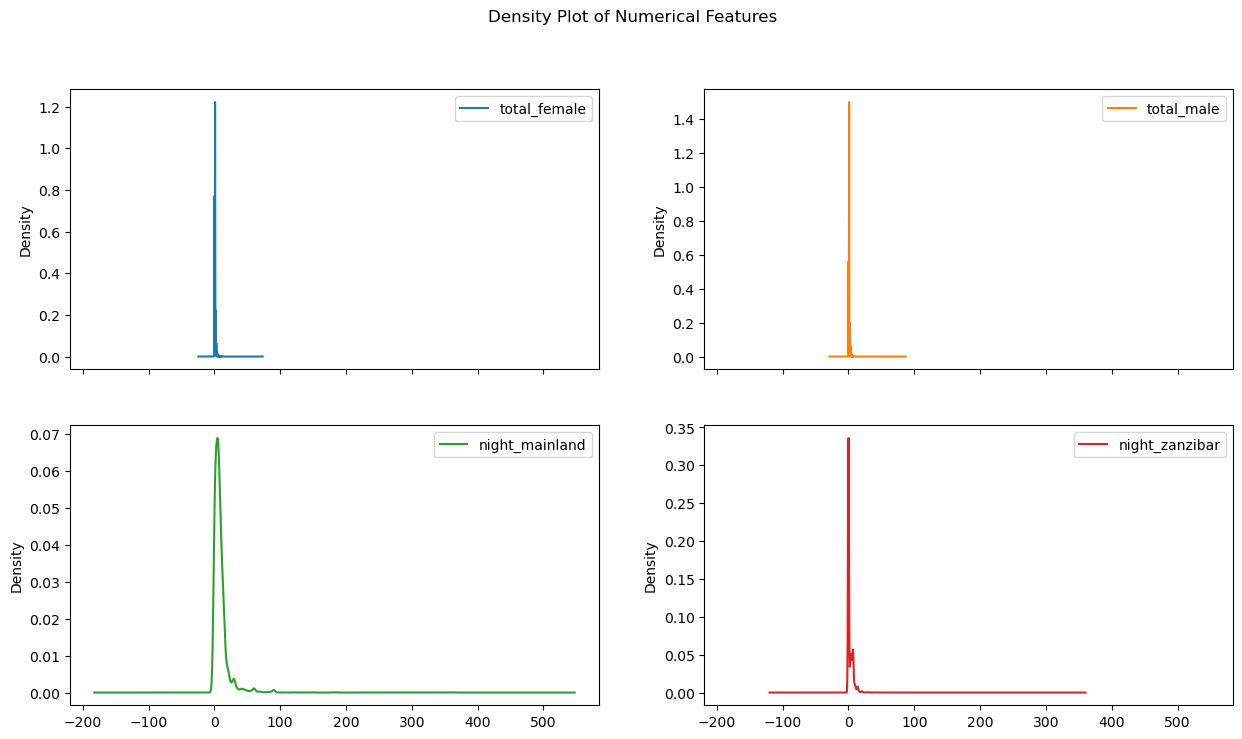

In [56]:
pd.DataFrame(df[NUMERIC_COLS]).plot(kind='density', subplots=True, figsize=(15, 8), title='Density Plot of Numerical Features', layout=(2, 2), sharex=True)

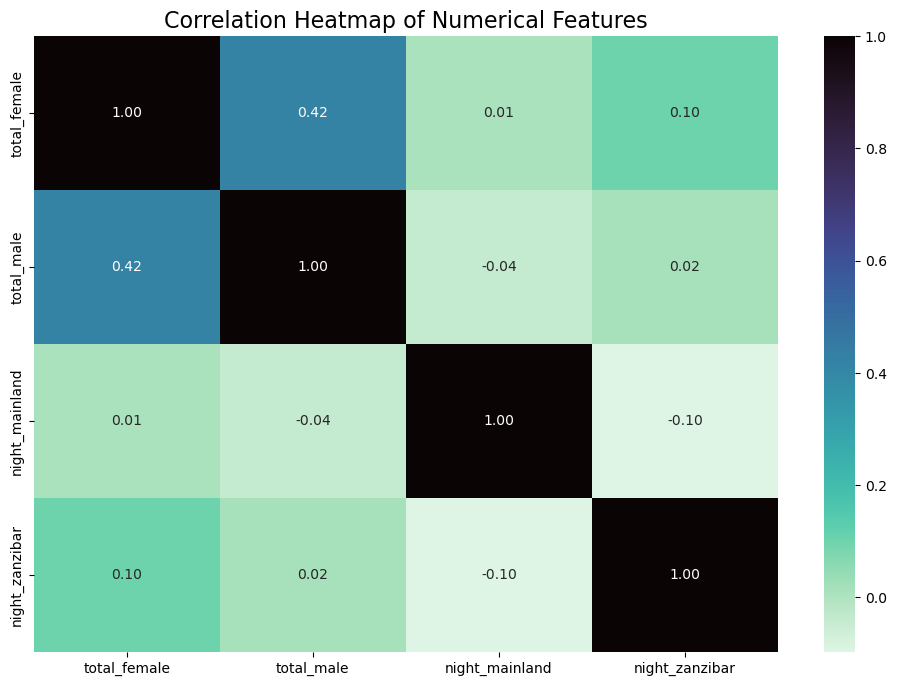

In [57]:
plt.figure(figsize=(12, 8))
sns.heatmap(df[NUMERIC_COLS].corr(), annot=True, cmap='mako_r', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features', fontsize=16)
plt.show()


## 7. Categorical Feature Analysis

Categorical variables are analyzed based on their frequency distributions.

This allows us to identify:

- Dominant categories.
- Rare categories.
- High-cardinality features.
- Potential data-entry inconsistencies.

## 8. Target Variable Analysis

The target variable is `cost_category`.

Before training any model, it is important to understand the distribution of the target classes.

This analysis helps determine whether the dataset suffers from class imbalance and whether additional strategies may be required during model training.

## 9. Correlation Analysis

Correlation analysis is used to examine linear relationships between numerical variables.

The purpose is not to automatically remove highly correlated features, but to identify potential relationships, redundancy, and patterns that may require further investigation.

## 10. Outlier Analysis

Outliers are observations that differ substantially from the majority of the data.

They may represent:

- Genuine extreme observations.
- Data-entry errors.
- Measurement errors.
- Rare but meaningful cases.

Therefore, outliers will not be removed automatically. Each relevant feature will be investigated before applying any treatment.

# 11. EDA Summary